In [4]:
import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
!pip install rasterio

In [11]:
import rasterio

In [23]:
%pip install altair

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 10.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [24]:
import altair as alt

In [25]:
import os
os.listdir(".")

['Tutorial03.ipynb',
 'Tutorial01.ipynb',
 '.DS_Store',
 'Tutorial03_output',
 'Tutorial02.ipynb',
 'tutorial02_map.pdf',
 'Assignement 01 Data in and Design',
 'tutorial03_maps.pdf',
 'data']

In [26]:
src = rasterio.open('/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/Tutorial01-data/Land_Cover_2010/landcover_2010_um.tif')

print(src.crs)
print(src.res)
print(src.bounds)
print(src.count, 'band(s),', src.width, 'x', src.height, 'cells')

EPSG:2263
(3.0, 3.0)
BoundingBox(left=991264.31878303, bottom=225638.84323376417, right=1004410.31878303, top=240623.84323376417)
1 band(s), 4382 x 4995 cells


In [27]:
landcover = src.read(1)

values, counts = np.unique(landcover, return_counts=True)
for v, c in zip(values, counts):
    print(v, c)

0 3844697
1 3852656
2 1653391
3 57132
4 322089
5 4870493
6 3239564
7 4048068


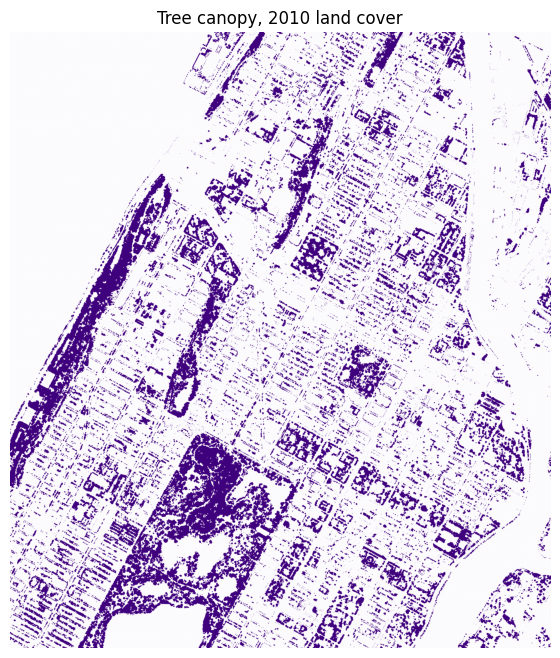

In [28]:
canopy = landcover == 1

plt.figure(figsize=(8, 8))
plt.imshow(canopy, cmap='Purples')
plt.axis('off')
plt.title('Tree canopy, 2010 land cover')
plt.show()

In [29]:
cells = canopy.sum()
acres = cells * 9 / 43560
print(f'{cells:,} canopy cells, about {acres:,.0f} acres, {canopy.mean():.1%} of the area')

3,852,656 canopy cells, about 796 acres, 17.6% of the area


In [30]:
df_StreetTree = pd.read_csv('/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/Tutorial01-data/2015_street_tree_census/2015_Street_Tree_Census_subset_um.csv')

df_StreetTree

,tree_id,block_id,created_at,tree_dbh,stump_diam,curb_loc,status,health,spc_latin,spc_common,...,boro_ct,state,latitude,longitude,x_sp,y_sp,council di,census tra,bin,bbl
0,198514,108318,09/02/2015,18,0,OnCurb,Alive,Good,Quercus palustris,pin oak,...,1019701,New York,40.802301,-73.962080,994748.4085,231579.2036,NaN,NaN,NaN,NaN
1,209919,108875,09/08/2015,9,0,OnCurb,Alive,Good,Platanus x acerifolia,London planetree,...,1020500,New York,40.808812,-73.963315,994405.4269,233951.0486,7.0,203.0,1084467.0,1.019730e+09
2,209921,108875,09/08/2015,3,0,OffsetFromCurb,Alive,Good,Platanus x acerifolia,London planetree,...,1020500,New York,40.808745,-73.963403,994380.9994,233926.6401,7.0,203.0,1084465.0,1.019730e+09
3,203887,108342,09/05/2015,5,0,OnCurb,Alive,Good,Quercus phellos,willow oak,...,1020101,New York,40.805726,-73.960719,995124.5475,232827.1256,7.0,20101.0,1056049.0,1.018670e+09
4,196440,108889,09/02/2015,5,0,OnCurb,Alive,Fair,Ulmus americana,American elm,...,1020500,New York,40.811145,-73.964123,994181.3574,234801.2532,7.0,205.0,1059835.0,1.019910e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12710,187077,106967,08/29/2015,4,0,OnCurb,Alive,Good,Ginkgo biloba,ginkgo,...,1019300,New York,40.800760,-73.960027,995316.9296,231017.8061,7.0,193.0,1055748.0,1.018458e+09
12711,196545,108887,09/02/2015,6,0,OnCurb,Alive,Good,Gleditsia triacanthos var. inermis,honeylocust,...,1020500,New York,40.808960,-73.965738,993734.6165,234005.0393,7.0,205.0,1059817.0,1.019900e+09
12712,189407,108374,08/30/2015,9,0,OnCurb,Alive,Fair,Ginkgo biloba,ginkgo,...,1020701,New York,40.807717,-73.959028,995592.3303,233552.8105,7.0,20701.0,1059503.0,1.019620e+09
12713,189408,108374,08/30/2015,2,0,OnCurb,Alive,Fair,Ginkgo biloba,ginkgo,...,1020701,New York,40.807769,-73.959152,995557.9685,233571.8823,7.0,20701.0,1059502.0,1.019620e+09


In [31]:
gdf_StreetTree = gpd.GeoDataFrame(df_StreetTree, geometry=gpd.points_from_xy(df_StreetTree['longitude'], df_StreetTree['latitude']), crs="EPSG:4326")

gdf_StreetTree.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [32]:
df_StreetTree['health'].unique()

<ArrowStringArray>
['Good', 'Fair', nan, 'Poor']
Length: 4, dtype: str

In [33]:
alt.data_transformers.disable_max_rows()

chart_StreetTree = alt.Chart(df_StreetTree).mark_circle().encode(
    longitude='longitude:Q',
    latitude='latitude:Q',
    color=alt.Color('health:N',
                    scale=alt.Scale(domain=['Good', 'Fair', 'Poor'],
                                    range=["#FF00F7", "#FF82FB", '#FFFFFF']),
                    legend=alt.Legend(title='Tree Health')),
    size=alt.Size('tree_dbh:Q',
                  scale=alt.Scale(range=[0, 225]),
                  legend=alt.Legend(title='Tree Diameter (inches)',
                                    symbolFillColor='white',
                                    symbolStrokeColor='white',
                                    symbolOpacity=1)),
    tooltip=['longitude:Q', 'latitude:Q', 'health', 'tree_dbh']
).project(
    type='mercator'
).properties(
    width=700,
    height=700
)

chart_StreetTree

alt.Chart(...)

In [35]:
gdf_Blocks = gpd.read_file('/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/Tutorial01-data/nycb2010_subset_um/nycb2010_um.gpkg').to_crs(epsg=4326)

gdf_Blocks

,CB2010,BoroCode,BoroName,CT2010,BCTCB2010,Shape_Leng,Shape_Area,geometry
0,1000,1,Manhattan,016800,10168001000,2106.253246,2.769941e+05,"MULTIPOLYGON (((-73.9479 40.79293, -73.94839 4..."
1,1000,1,Manhattan,017800,10178001000,1947.634689,1.861154e+05,"MULTIPOLYGON (((-73.93174 40.79699, -73.9322 4..."
2,1000,1,Manhattan,018000,10180001000,2059.932028,1.898429e+05,"MULTIPOLYGON (((-73.93591 40.79531, -73.93595 ..."
3,1000,1,Manhattan,018200,10182001000,1583.485495,1.436238e+05,"MULTIPOLYGON (((-73.94113 40.7993, -73.94162 4..."
4,1000,1,Manhattan,018400,10184001000,1550.256558,1.343552e+05,"MULTIPOLYGON (((-73.94181 40.80124, -73.94227 ..."
...,...,...,...,...,...,...,...,...
575,1001,1,Manhattan,014300,10143001001,7292.302131,2.282271e+06,"MULTIPOLYGON (((-73.94975 40.7971, -73.94972 4..."
576,2001,1,Manhattan,018600,10186002001,2481.700884,2.453932e+05,"MULTIPOLYGON (((-73.94879 40.79748, -73.94906 ..."
577,2002,1,Manhattan,018600,10186002002,454.544435,9.237289e+03,"MULTIPOLYGON (((-73.94906 40.7971, -73.94923 4..."
578,4002,1,Manhattan,017000,10170004002,879.671868,4.298733e+04,"MULTIPOLYGON (((-73.94139 40.79104, -73.94157 ..."


In [36]:
chart_Blocks = alt.Chart(gdf_Blocks).mark_geoshape(
    stroke="#ffffff",
    strokeWidth=0.5,
    fillOpacity=0
).encode(
    color=alt.value('white')
).project(
    type='mercator'
).properties(
    width=700,
    height=700,
)

chart_Blocks

alt.Chart(...)

In [38]:
combined_Chart = (chart_Blocks + chart_StreetTree).properties(
    background='#0000ff'
).configure_legend(
    labelColor='white',
    titleColor='white'
)

combined_Chart

alt.LayerChart(...)

In [39]:
gdf_joined = gpd.sjoin(gdf_Blocks, gdf_StreetTree, how='right', predicate='contains')

In [40]:
df_counts = gdf_joined.groupby('BCTCB2010').agg(
    tree_count=('tree_id', 'count'),
    tree_dbh_sum=('tree_dbh', 'sum')
).reset_index()

In [41]:
# Perform spatial join using sjoin
gdf_joined = gpd.sjoin(gdf_Blocks, gdf_StreetTree, how='right', predicate='contains')

# Group by block and count the trees and sum their diameters
df_counts = gdf_joined.groupby('BCTCB2010').agg(
    tree_count=('tree_id', 'count'),
    tree_dbh_sum=('tree_dbh', 'sum')
).reset_index()

# Merge the summaries back to the block GeoDataFrame; blocks with no trees get 0
gdf_TreeBlocks = gdf_Blocks.merge(df_counts, on='BCTCB2010', how='left')
gdf_TreeBlocks[['tree_count', 'tree_dbh_sum']] = gdf_TreeBlocks[['tree_count', 'tree_dbh_sum']].fillna(0)

gdf_TreeBlocks

,CB2010,BoroCode,BoroName,CT2010,BCTCB2010,Shape_Leng,Shape_Area,geometry,tree_count,tree_dbh_sum
0,1000,1,Manhattan,016800,10168001000,2106.253246,2.769941e+05,"MULTIPOLYGON (((-73.9479 40.79293, -73.94839 4...",9.0,49.0
1,1000,1,Manhattan,017800,10178001000,1947.634689,1.861154e+05,"MULTIPOLYGON (((-73.93174 40.79699, -73.9322 4...",34.0,258.0
2,1000,1,Manhattan,018000,10180001000,2059.932028,1.898429e+05,"MULTIPOLYGON (((-73.93591 40.79531, -73.93595 ...",16.0,55.0
3,1000,1,Manhattan,018200,10182001000,1583.485495,1.436238e+05,"MULTIPOLYGON (((-73.94113 40.7993, -73.94162 4...",23.0,162.0
4,1000,1,Manhattan,018400,10184001000,1550.256558,1.343552e+05,"MULTIPOLYGON (((-73.94181 40.80124, -73.94227 ...",35.0,260.0
...,...,...,...,...,...,...,...,...,...,...
575,1001,1,Manhattan,014300,10143001001,7292.302131,2.282271e+06,"MULTIPOLYGON (((-73.94975 40.7971, -73.94972 4...",75.0,1172.0
576,2001,1,Manhattan,018600,10186002001,2481.700884,2.453932e+05,"MULTIPOLYGON (((-73.94879 40.79748, -73.94906 ...",50.0,512.0
577,2002,1,Manhattan,018600,10186002002,454.544435,9.237289e+03,"MULTIPOLYGON (((-73.94906 40.7971, -73.94923 4...",4.0,36.0
578,4002,1,Manhattan,017000,10170004002,879.671868,4.298733e+04,"MULTIPOLYGON (((-73.94139 40.79104, -73.94157 ...",5.0,38.0


In [42]:
gdf_TreeBlocks['avg_diameter'] = gdf_TreeBlocks['tree_dbh_sum'] / gdf_TreeBlocks['tree_count']

In [43]:
gdf_TreeBlocks.sort_values('tree_count', ascending=False).head(10)

,CB2010,BoroCode,BoroName,CT2010,BCTCB2010,Shape_Leng,Shape_Area,geometry,tree_count,tree_dbh_sum,avg_diameter
572,1000,1,Manhattan,019701,10197011000,8800.522830,1.745735e+06,"MULTIPOLYGON (((-73.95685 40.81086, -73.95643 ...",145.0,2522.0,17.393103
518,1002,1,Manhattan,020500,10205001002,5352.133378,1.249582e+06,"MULTIPOLYGON (((-73.96381 40.81311, -73.96384 ...",129.0,2099.0,16.271318
446,1007,1,Manhattan,020500,10205001007,2728.510147,3.308187e+05,"MULTIPOLYGON (((-73.96206 40.81053, -73.96249 ...",101.0,887.0,8.782178
350,2000,1,Manhattan,019800,10198002000,4075.077404,1.037698e+06,"MULTIPOLYGON (((-73.94275 40.80574, -73.94188 ...",95.0,754.0,7.936842
297,1000,1,Manhattan,021703,10217031000,4682.612712,6.631277e+05,"MULTIPOLYGON (((-73.94724 40.82175, -73.94608 ...",81.0,638.0,7.876543
48,1002,1,Manhattan,019500,10195001002,3429.743789,7.179171e+05,"MULTIPOLYGON (((-73.96856 40.80485, -73.96933 ...",75.0,1192.0,15.893333
575,1001,1,Manhattan,014300,10143001001,7292.302131,2.282271e+06,"MULTIPOLYGON (((-73.94975 40.7971, -73.94972 4...",75.0,1172.0,15.626667
290,1002,1,Manhattan,021703,10217031002,3925.818664,9.327908e+05,"MULTIPOLYGON (((-73.94973 40.81792, -73.94984 ...",75.0,596.0,7.946667
51,1002,1,Manhattan,019900,10199001002,3426.393019,6.577715e+05,"MULTIPOLYGON (((-73.96701 40.8076, -73.9674 40...",72.0,1200.0,16.666667
352,3001,1,Manhattan,017800,10178003001,2958.683218,5.750688e+05,"MULTIPOLYGON (((-73.9295 40.796, -73.92958 40....",67.0,479.0,7.149254


In [44]:
chart_TreeDiameter = alt.Chart(gdf_TreeBlocks).mark_geoshape(
    stroke='#0000ff',
    strokeWidth=1
).encode(
    color=alt.Color('avg_diameter:Q', scale=alt.Scale(range=["#3636FE", "#F0F0FF"])),
    tooltip=['BCTCB2010:N', 'tree_count:Q', 'avg_diameter:Q']
).project(
    type='mercator'
).properties(
    width=700,
    height=700
)

chart_TreeDiameter

alt.Chart(...)

In [45]:
color=alt.Color('avg_diameter:Q', scale=alt.Scale(scheme='greens', type='quantile')),

In [46]:
Final_Chart = (chart_TreeDiameter + chart_StreetTree).properties(
    width=1056,
    height=816,
    autosize=alt.AutoSizeParams(
        type="fit",
        contains="padding"
    ),
    background="#0000ff",
    padding=20
).configure_legend(
    labelColor="white",
    titleColor="white"
)

Final_Chart

alt.LayerChart(...)

In [48]:
%pip install vl-convert-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.7/29.7 MB 11.4 MB/s  0:00:02 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [49]:
Final_Chart.save("tutorial01_map.pdf")